# Phase 4 - Transferencia a Otra Divisa con Embedding + Clustering (v2 Mejorado)

Objetivo: mejorar la calidad del embedding para segmentacion automatica en EURUSD usando:
- normalizacion por forma (log-precio anclado y escalado robusto por volatilidad local),
- encoder de atencion con pooling aprendido,
- perdida compuesta (reconstruccion + derivada + consistencia entre vistas).


In [1]:
import math
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 260)
pd.set_option('display.width', 320)


In [2]:
# =========================
# Config
# =========================
SYMBOL_TARGET = 'EURUSD'
DATE_START = None  # usar inicio completo disponible
DATE_END = None    # usar fin completo disponible

DATA_H1_DIR = Path('./data/Dataset_H1_v1/parquet_h1')
TARGET_PRICE_PATH = DATA_H1_DIR / f'{SYMBOL_TARGET}.parquet'

# Referencia USDJPY ya extraida en phase3
REF_CATALOG_PATH = Path('./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_extracted_catalog.parquet')
REF_LONG_PATH = Path('./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_extracted_long.parquet')
REF_SPLIT_PATH = Path('./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_split_temporal.parquet')
REF_PRICE_PATH = DATA_H1_DIR / 'USDJPY.parquet'

OUTPUT_DIR = Path(f'./phases/phase04_transfer_clustering/output_transfer_{SYMBOL_TARGET}_full_v2')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_CATALOG_PARQUET = OUTPUT_DIR / f'{SYMBOL_TARGET}_segments_catalog.parquet'
TARGET_CATALOG_CSV = OUTPUT_DIR / f'{SYMBOL_TARGET}_segments_catalog.csv'
TARGET_LONG_PARQUET = OUTPUT_DIR / f'{SYMBOL_TARGET}_segments_long.parquet'
TARGET_LONG_CSV = OUTPUT_DIR / f'{SYMBOL_TARGET}_segments_long.csv'

TARGET_ASSIGN_PARQUET = OUTPUT_DIR / f'{SYMBOL_TARGET}_segment_cluster_assignments.parquet'
TARGET_ASSIGN_CSV = OUTPUT_DIR / f'{SYMBOL_TARGET}_segment_cluster_assignments.csv'
TARGET_SELECTED_PARQUET = OUTPUT_DIR / f'{SYMBOL_TARGET}_selected_segments.parquet'
TARGET_SELECTED_CSV = OUTPUT_DIR / f'{SYMBOL_TARGET}_selected_segments.csv'

REF_CLUSTER_PROFILE_CSV = OUTPUT_DIR / 'reference_usdjpy_cluster_profile.csv'
TRAIN_HISTORY_CSV = OUTPUT_DIR / 'transfer_encoder_train_history.csv'
EMB_NPZ = OUTPUT_DIR / f'{SYMBOL_TARGET}_embeddings_transfer.npz'
MODEL_WEIGHTS = OUTPUT_DIR / 'transfer_attention_encoder.pt'

SEED = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# Segmentacion automatica en divisa target
EVENT_Q = 0.985
EVENT_MAX_GAP = 10
SEG_PREPAD = 6
SEG_POSTPAD = 10
MIN_SEG_BARS = 6
MAX_SEG_BARS = 176
MAX_OVERLAP = 0.60

# Encoder/Embedding v2
MAX_LEN = 176
D_MODEL = 128
EMB_DIM = 64
N_HEAD = 8
N_LAYERS = 4
FF_DIM = 256
DROPOUT = 0.12

BATCH_SIZE = 64
EPOCHS = 90
LR = 7e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 18
NOISE_STD = 0.03
MASK_DROPOUT = 0.10

# Pesos de perdida
LOSS_RECON_W = 1.00
LOSS_DERIV_W = 0.35
LOSS_CONS_W = 0.10

# Clustering y seleccion
K_CLUSTERS = 10
HORIZON_HOURS = 24
MIN_CLUSTER_N = 20
ABS_MEAN_RET_MIN = 10.0

print('SYMBOL_TARGET =', SYMBOL_TARGET)
print('TARGET_PRICE_PATH =', TARGET_PRICE_PATH)
print('DEVICE =', DEVICE)
print('OUTPUT_DIR =', OUTPUT_DIR)


SYMBOL_TARGET = EURUSD
TARGET_PRICE_PATH = ./data/Dataset_H1_v1/parquet_h1/EURUSD.parquet
DEVICE = cuda
OUTPUT_DIR = ./phases/phase04_transfer_clustering/output_transfer_EURUSD_full_v2


In [3]:
# =========================
# Reproducibilidad
# =========================
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

try:
    torch.set_float32_matmul_precision('high')
except Exception:
    pass


In [4]:
# =========================
# Helpers
# =========================
def pip_size(symbol: str) -> float:
    return 0.01 if str(symbol).upper().endswith('JPY') else 0.0001


def robust_zscore(x: np.ndarray, eps: float = 1e-8) -> np.ndarray:
    x = np.asarray(x, dtype=float)
    med = np.nanmedian(x)
    mad = np.nanmedian(np.abs(x - med))
    if not np.isfinite(mad) or mad < eps:
        m = np.nanmean(x)
        s = np.nanstd(x)
        if not np.isfinite(s) or s < eps:
            return np.zeros_like(x, dtype=float)
        z = (x - m) / (s + eps)
    else:
        z = (x - med) / (1.4826 * mad + eps)
    return np.clip(z, -8.0, 8.0)


def overlap_ratio(a0: int, a1: int, b0: int, b1: int) -> float:
    inter = max(0, min(a1, b1) - max(a0, b0) + 1)
    la = max(1, a1 - a0 + 1)
    lb = max(1, b1 - b0 + 1)
    return inter / float(min(la, lb))


def nms_segments(df: pd.DataFrame, max_overlap: float = 0.6) -> pd.DataFrame:
    if df.empty:
        return df.copy()
    d = df.sort_values('score_event', ascending=False).reset_index(drop=True)
    keep = []
    for _, r in d.iterrows():
        s0, s1 = int(r['start_idx']), int(r['end_idx'])
        ok = True
        for k in keep:
            ov = overlap_ratio(s0, s1, int(k['start_idx']), int(k['end_idx']))
            if ov > max_overlap:
                ok = False
                break
        if ok:
            keep.append(r)
    out = pd.DataFrame(keep).sort_values('start_idx').reset_index(drop=True)
    return out


def preprocess_sequence(close_arr: np.ndarray, eps: float = 1e-8) -> np.ndarray:
    # Invariante a nivel/precio absoluto y robusta a escala volatilidad
    x = np.asarray(close_arr, dtype=float)
    if len(x) == 0:
        return np.zeros(0, dtype=np.float32)
    x = np.clip(x, eps, None)
    logp = np.log(x)
    y = logp - logp[0]

    dy = np.diff(y, prepend=y[0])
    med = np.nanmedian(dy)
    mad = np.nanmedian(np.abs(dy - med))
    scale = 1.4826 * mad if np.isfinite(mad) and mad > eps else np.nan
    if not np.isfinite(scale) or scale < eps:
        scale = np.nanstd(dy)
    if not np.isfinite(scale) or scale < eps:
        scale = np.nanstd(y)
    if not np.isfinite(scale) or scale < eps:
        scale = 1.0

    z = y / float(scale)
    z = np.clip(z, -8.0, 8.0)
    return z.astype(np.float32)


def load_price(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f'No existe path: {path}')
    keep = ['timestamp', 'open', 'high', 'low', 'close']
    df = pd.read_parquet(path, columns=keep).copy()
    df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
    for c in ['open', 'high', 'low', 'close']:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    df = df.dropna(subset=['timestamp', 'close'])
    df = df.sort_values('timestamp').drop_duplicates('timestamp', keep='last').reset_index(drop=True)
    return df


def compute_forward_pips(df_price: pd.DataFrame, ts_vec: pd.Series, symbol: str, horizon_hours: int = 24) -> np.ndarray:
    idx = df_price['timestamp'].to_numpy(dtype='datetime64[ns]')
    close = df_price['close'].to_numpy(dtype=float)
    ts = pd.to_datetime(ts_vec, errors='coerce').to_numpy(dtype='datetime64[ns]')
    pos = np.searchsorted(idx, ts, side='left')

    out = np.full(len(ts), np.nan, dtype=float)
    pip = pip_size(symbol)
    for i in range(len(ts)):
        p0 = pos[i]
        p1 = p0 + int(horizon_hours)
        if p0 < 0 or p1 >= len(idx):
            continue
        if idx[p0] != ts[i]:
            continue
        out[i] = (close[p1] - close[p0]) / pip
    return out


In [5]:
# =========================
# 1) Cargar nueva divisa desde phase1
# =========================
if not TARGET_PRICE_PATH.exists():
    raise FileNotFoundError(
        f'No existe {TARGET_PRICE_PATH}.\n'
        'Genera el H1 con phase1 (build_h1_dataset.py) para este simbolo y vuelve a ejecutar.'
    )

PX_T = load_price(TARGET_PRICE_PATH)
if DATE_START is not None:
    PX_T = PX_T[PX_T['timestamp'] >= DATE_START]
if DATE_END is not None:
    PX_T = PX_T[PX_T['timestamp'] <= DATE_END]
PX_T = PX_T.copy().reset_index(drop=True)
PX_T['idx'] = np.arange(len(PX_T), dtype=int)

if PX_T.empty:
    raise RuntimeError('No hay datos target en el rango temporal configurado.')

print('TARGET rows =', len(PX_T))
print('TARGET range =', PX_T['timestamp'].min(), '->', PX_T['timestamp'].max())
display(PX_T.head(3))


TARGET rows = 155390
TARGET range = 2000-05-30 17:00:00 -> 2025-12-05 16:00:00


,timestamp,open,high,low,close,idx
0,2000-05-30 17:00:00,0.9302,0.9305,0.9297,0.9297,0
1,2000-05-30 18:00:00,0.9298,0.9300,0.9296,0.9296,1
2,2000-05-30 19:00:00,0.9297,0.9305,0.9293,0.9305,2


In [6]:
# =========================
# 2) Segmentacion automatica en target
# =========================
# Eventos por shock de retorno + expansion de rango
close = PX_T['close'].to_numpy(dtype=float)
ret1 = np.zeros(len(close), dtype=float)
if len(close) > 1:
    prev = np.clip(close[:-1], 1e-12, None)
    curr = np.clip(close[1:], 1e-12, None)
    ret1[1:] = np.log(curr / prev)

range12 = (PX_T['high'].rolling(12, min_periods=3).max() - PX_T['low'].rolling(12, min_periods=3).min()).to_numpy(dtype=float)
drange = np.zeros_like(range12)
drange[1:] = np.diff(range12)

z_ret = np.abs(robust_zscore(ret1))
z_rng = np.abs(robust_zscore(drange))
score = 0.7 * z_ret + 0.3 * z_rng

thr = float(np.nanquantile(score[np.isfinite(score)], EVENT_Q))
event_idx = np.where(score >= thr)[0]

print('event threshold =', round(thr, 4), '| events =', len(event_idx))

# Agrupar eventos cercanos
clusters = []
if len(event_idx) > 0:
    cur = [int(event_idx[0])]
    for i in event_idx[1:]:
        i = int(i)
        if i - cur[-1] <= EVENT_MAX_GAP:
            cur.append(i)
        else:
            clusters.append(cur)
            cur = [i]
    clusters.append(cur)

rows = []
for c in clusters:
    s = max(0, min(c) - SEG_PREPAD)
    e = min(len(PX_T) - 1, max(c) + SEG_POSTPAD)
    n = e - s + 1
    if n < MIN_SEG_BARS:
        continue
    if n > MAX_SEG_BARS:
        e = min(len(PX_T) - 1, s + MAX_SEG_BARS - 1)
        n = e - s + 1

    w = PX_T.iloc[s:e+1]
    ps = pip_size(SYMBOL_TARGET)
    move_pips = (float(w['close'].iloc[-1]) - float(w['close'].iloc[0])) / ps
    range_pips = (float(w['high'].max()) - float(w['low'].min())) / ps
    sc = float(np.nanmax(score[s:e+1]))

    rows.append({
        'symbol': SYMBOL_TARGET,
        'start_idx': int(s),
        'end_idx': int(e),
        'start_ts': pd.Timestamp(w['timestamp'].iloc[0]),
        'end_ts': pd.Timestamp(w['timestamp'].iloc[-1]),
        'n_bars': int(n),
        'move_pips': float(move_pips),
        'range_pips': float(range_pips),
        'score_event': sc,
        'source': 'phase4_auto_event_segmentation',
    })

SEG_T = pd.DataFrame(rows)
if SEG_T.empty:
    raise RuntimeError('No se generaron segmentos target con la configuracion actual.')

SEG_T = nms_segments(SEG_T, max_overlap=MAX_OVERLAP)
SEG_T['global_segment_id'] = [f'{SYMBOL_TARGET}_seg_{i:05d}' for i in range(len(SEG_T))]
SEG_T = SEG_T.sort_values('start_ts').reset_index(drop=True)

print('Target segments after NMS =', len(SEG_T))
display(SEG_T.head(10))


event threshold = 5.9279 | events = 2331


Target segments after NMS = 1748


,symbol,start_idx,end_idx,start_ts,end_ts,n_bars,move_pips,range_pips,score_event,source,global_segment_id
0,EURUSD,10,33,2000-05-31 04:00:00,2000-06-01 03:00:00,24,44.000149,231.000185,8.000000,phase4_auto_event_segmentation,EURUSD_seg_00000
1,EURUSD,28,44,2000-05-31 22:00:00,2000-06-01 14:00:00,17,-37.000179,93.000531,6.007475,phase4_auto_event_segmentation,EURUSD_seg_00001
2,EURUSD,50,72,2000-06-01 20:00:00,2000-06-04 20:00:00,23,131.000280,196.000338,8.000000,phase4_auto_event_segmentation,EURUSD_seg_00002
3,EURUSD,97,119,2000-06-05 21:00:00,2000-06-06 19:00:00,23,91.000199,147.000551,8.000000,phase4_auto_event_segmentation,EURUSD_seg_00003
4,EURUSD,146,165,2000-06-07 23:00:00,2000-06-08 21:00:00,20,-36.999583,191.999674,8.000000,phase4_auto_event_segmentation,EURUSD_seg_00004
5,EURUSD,168,184,2000-06-09 02:00:00,2000-06-12 00:00:00,17,-48.999786,95.999837,6.677088,phase4_auto_event_segmentation,EURUSD_seg_00005
6,EURUSD,204,226,2000-06-12 20:00:00,2000-06-13 18:00:00,23,70.000291,105.000138,6.629955,phase4_auto_event_segmentation,EURUSD_seg_00006
7,EURUSD,253,269,2000-06-14 21:00:00,2000-06-15 13:00:00,17,-41.000247,102.999806,6.023345,phase4_auto_event_segmentation,EURUSD_seg_00007
8,EURUSD,274,296,2000-06-15 18:00:00,2000-06-18 21:00:00,23,103.999972,138.999820,7.067356,phase4_auto_event_segmentation,EURUSD_seg_00008
9,EURUSD,297,313,2000-06-18 22:00:00,2000-06-19 14:00:00,17,-58.000088,119.999647,7.528287,phase4_auto_event_segmentation,EURUSD_seg_00009


In [7]:
# =========================
# 3) Extraer long-format target
# =========================
long_rows = []
for _, r in SEG_T.iterrows():
    sid = r['global_segment_id']
    s = int(r['start_idx'])
    e = int(r['end_idx'])
    w = PX_T.iloc[s:e+1]
    for i, (_, rr) in enumerate(w.iterrows()):
        long_rows.append({
            'global_segment_id': sid,
            'step': int(i),
            'timestamp': pd.Timestamp(rr['timestamp']),
            'open': float(rr['open']),
            'high': float(rr['high']),
            'low': float(rr['low']),
            'close': float(rr['close']),
        })

LONG_T = pd.DataFrame(long_rows)

SEG_T.to_parquet(TARGET_CATALOG_PARQUET, index=False)
SEG_T.to_csv(TARGET_CATALOG_CSV, index=False)
LONG_T.to_parquet(TARGET_LONG_PARQUET, index=False)
LONG_T.to_csv(TARGET_LONG_CSV, index=False)

print('Saved target extraction:')
print(' -', TARGET_CATALOG_PARQUET)
print(' -', TARGET_LONG_PARQUET)
print('LONG rows =', len(LONG_T))


Saved target extraction:
 - ./phases/phase04_transfer_clustering/output_transfer_EURUSD_full_v2/EURUSD_segments_catalog.parquet
 - ./phases/phase04_transfer_clustering/output_transfer_EURUSD_full_v2/EURUSD_segments_long.parquet
LONG rows = 32138


In [8]:
# =========================
# 4) Cargar referencia USDJPY (train encoder)
# =========================
for p in [REF_CATALOG_PATH, REF_LONG_PATH, REF_SPLIT_PATH, REF_PRICE_PATH]:
    if not p.exists():
        raise FileNotFoundError(f'Falta archivo de referencia: {p}')

REF_CAT = pd.read_parquet(REF_CATALOG_PATH).copy()
REF_LONG = pd.read_parquet(REF_LONG_PATH).copy().sort_values(['global_segment_id', 'step'])
REF_SPLIT = pd.read_parquet(REF_SPLIT_PATH).copy()
REF_PX = load_price(REF_PRICE_PATH)

REF_CAT = REF_CAT.merge(REF_SPLIT[['global_segment_id', 'split']], on='global_segment_id', how='left')
REF_CAT['split'] = REF_CAT['split'].fillna('train')

# map sid -> close sequence
ref_seq_map = {
    sid: g['close'].to_numpy(dtype=float)
    for sid, g in REF_LONG.groupby('global_segment_id', sort=False)
}

rows_ref = []
for _, r in REF_CAT.iterrows():
    sid = str(r['global_segment_id'])
    seq = ref_seq_map.get(sid)
    if seq is None or len(seq) < MIN_SEG_BARS:
        continue
    x = preprocess_sequence(seq)
    rows_ref.append({
        'global_segment_id': sid,
        'split': str(r.get('split', 'train')),
        'start_ts': pd.Timestamp(r.get('start_ts')),
        'seq': x,
        'length': int(len(x)),
    })

DF_REF = pd.DataFrame(rows_ref).sort_values('start_ts').reset_index(drop=True)

# target sequences
tar_seq_map = {
    sid: g['close'].to_numpy(dtype=float)
    for sid, g in LONG_T.groupby('global_segment_id', sort=False)
}
rows_tar = []
for _, r in SEG_T.iterrows():
    sid = str(r['global_segment_id'])
    seq = tar_seq_map.get(sid)
    if seq is None or len(seq) < MIN_SEG_BARS:
        continue
    x = preprocess_sequence(seq)
    rows_tar.append({
        'global_segment_id': sid,
        'start_ts': pd.Timestamp(r['start_ts']),
        'seq': x,
        'length': int(len(x)),
    })
DF_TAR = pd.DataFrame(rows_tar).sort_values('start_ts').reset_index(drop=True)

print('REF sequences =', len(DF_REF), '| TAR sequences =', len(DF_TAR))
print('REF split counts:')
print(DF_REF['split'].value_counts().to_string())


REF sequences = 991 | TAR sequences = 1748
REF split counts:
split
train    695
test     149
val      147


In [9]:
# =========================
# 5) Padding arrays
# =========================
def build_padded(df_seq: pd.DataFrame, max_len: int):
    n = len(df_seq)
    X = np.zeros((n, max_len), dtype=np.float32)
    M = np.zeros((n, max_len), dtype=bool)
    L = np.zeros(n, dtype=np.int32)

    trunc = 0
    for i, seq in enumerate(df_seq['seq']):
        s = np.asarray(seq, dtype=np.float32)
        if len(s) > max_len:
            s = s[-max_len:]
            trunc += 1
        ln = len(s)
        X[i, :ln] = s
        M[i, :ln] = True
        L[i] = ln
    return X, M, L, trunc

X_REF, M_REF, L_REF, trunc_ref = build_padded(DF_REF, MAX_LEN)
X_TAR, M_TAR, L_TAR, trunc_tar = build_padded(DF_TAR, MAX_LEN)

print('X_REF =', X_REF.shape, '| trunc_ref =', trunc_ref)
print('X_TAR =', X_TAR.shape, '| trunc_tar =', trunc_tar)


X_REF = (991, 176) | trunc_ref = 0
X_TAR = (1748, 176) | trunc_tar = 0


In [10]:
# =========================
# 6) Dataset + modelo atencion (v2)
# =========================
class SegmentDataset(Dataset):
    def __init__(self, x: np.ndarray, m: np.ndarray, idx: np.ndarray):
        self.x = torch.from_numpy(x[idx]).float()
        self.m = torch.from_numpy(m[idx]).bool()
    def __len__(self):
        return len(self.x)
    def __getitem__(self, i):
        return self.x[i], self.m[i]


class AttentionPool(nn.Module):
    def __init__(self, d_model: int):
        super().__init__()
        self.query = nn.Parameter(torch.randn(d_model) * 0.02)

    def forward(self, h: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        scale = math.sqrt(h.shape[-1])
        logits = (h * self.query.view(1, 1, -1)).sum(dim=-1) / scale
        logits = logits.masked_fill(~mask, -1e4)
        attn = torch.softmax(logits, dim=1)
        pooled = torch.einsum('bl,bld->bd', attn, h)
        return pooled


class SegmentAttentionAutoencoder(nn.Module):
    def __init__(self, max_len: int, d_model: int, emb_dim: int, n_head: int, n_layers: int, ff_dim: int, dropout: float):
        super().__init__()
        self.max_len = max_len
        self.in_proj = nn.Linear(1, d_model)
        self.pos_emb = nn.Parameter(torch.randn(1, max_len, d_model) * 0.02)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_head,
            dim_feedforward=ff_dim,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.pool = AttentionPool(d_model)

        self.to_emb = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, emb_dim),
        )

        self.decoder = nn.Sequential(
            nn.Linear(emb_dim, d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, max_len),
        )

    def forward(self, x: torch.Tensor, mask: torch.Tensor, noise_std: float = 0.0, mask_drop: float = 0.0):
        _, L = x.shape
        xx = x

        if self.training and noise_std > 0:
            xx = xx + noise_std * torch.randn_like(xx)

        if self.training and mask_drop > 0:
            keep = (torch.rand_like(xx) < (1.0 - mask_drop)) | (~mask)
            xx = xx * keep.float()

        h = self.in_proj(xx.unsqueeze(-1))
        h = h + self.pos_emb[:, :L, :]
        h = self.encoder(h, src_key_padding_mask=~mask)

        pooled = self.pool(h, mask)
        z = self.to_emb(pooled)
        recon = self.decoder(z)[:, :L]
        return z, recon


def masked_huber(recon: torch.Tensor, target: torch.Tensor, mask: torch.Tensor, delta: float = 0.5) -> torch.Tensor:
    w = mask.float()
    den = w.sum().clamp(min=1.0)
    err = torch.abs(recon - target)
    loss = torch.where(err < delta, 0.5 * (err ** 2) / delta, err - 0.5 * delta)
    return (loss * w).sum() / den


def masked_derivative_huber(recon: torch.Tensor, target: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
    if recon.shape[1] < 2:
        return torch.zeros((), device=recon.device)
    dr = recon[:, 1:] - recon[:, :-1]
    dt = target[:, 1:] - target[:, :-1]
    dm = mask[:, 1:] & mask[:, :-1]
    return masked_huber(dr, dt, dm, delta=0.35)


def consistency_cosine(z1: torch.Tensor, z2: torch.Tensor) -> torch.Tensor:
    c = F.cosine_similarity(z1, z2, dim=-1)
    return 1.0 - c.mean()


In [11]:
# =========================
# 7) Entrenar encoder en referencia USDJPY (v2)
# =========================
ref_split = DF_REF['split'].to_numpy()
idx_train = np.where(ref_split == 'train')[0]
idx_val = np.where(ref_split == 'val')[0]

pin = DEVICE == 'cuda'
train_loader = DataLoader(
    SegmentDataset(X_REF, M_REF, idx_train),
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    pin_memory=pin,
)
val_loader = DataLoader(
    SegmentDataset(X_REF, M_REF, idx_val),
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    pin_memory=pin,
) if len(idx_val) > 0 else None

model = SegmentAttentionAutoencoder(
    max_len=MAX_LEN,
    d_model=D_MODEL,
    emb_dim=EMB_DIM,
    n_head=N_HEAD,
    n_layers=N_LAYERS,
    ff_dim=FF_DIM,
    dropout=DROPOUT,
).to(DEVICE)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=LR * 0.05)

history = []
best_val = float('inf')
best_state = None
bad = 0

for ep in range(1, EPOCHS + 1):
    model.train()
    tr_total, tr_rec, tr_der, tr_cons = [], [], [], []

    for xb, mb in train_loader:
        xb = xb.to(DEVICE, non_blocking=True)
        mb = mb.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        z1, rec1 = model(xb, mb, noise_std=NOISE_STD, mask_drop=MASK_DROPOUT)
        z2, rec2 = model(xb, mb, noise_std=NOISE_STD, mask_drop=MASK_DROPOUT)

        l_rec = 0.5 * (masked_huber(rec1, xb, mb) + masked_huber(rec2, xb, mb))
        l_der = 0.5 * (masked_derivative_huber(rec1, xb, mb) + masked_derivative_huber(rec2, xb, mb))
        l_cons = consistency_cosine(z1, z2)
        loss = LOSS_RECON_W * l_rec + LOSS_DERIV_W * l_der + LOSS_CONS_W * l_cons

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        tr_total.append(float(loss.detach().cpu().item()))
        tr_rec.append(float(l_rec.detach().cpu().item()))
        tr_der.append(float(l_der.detach().cpu().item()))
        tr_cons.append(float(l_cons.detach().cpu().item()))

    scheduler.step()
    tr = float(np.mean(tr_total)) if tr_total else np.nan
    tr_r = float(np.mean(tr_rec)) if tr_rec else np.nan
    tr_d = float(np.mean(tr_der)) if tr_der else np.nan
    tr_c = float(np.mean(tr_cons)) if tr_cons else np.nan

    va = np.nan
    va_r = np.nan
    va_d = np.nan
    if val_loader is not None:
        model.eval()
        v_tot, v_rec, v_der = [], [], []
        with torch.no_grad():
            for xb, mb in val_loader:
                xb = xb.to(DEVICE, non_blocking=True)
                mb = mb.to(DEVICE, non_blocking=True)
                _, rec = model(xb, mb, noise_std=0.0, mask_drop=0.0)
                l_rec = masked_huber(rec, xb, mb)
                l_der = masked_derivative_huber(rec, xb, mb)
                l_tot = LOSS_RECON_W * l_rec + LOSS_DERIV_W * l_der
                v_tot.append(float(l_tot.detach().cpu().item()))
                v_rec.append(float(l_rec.detach().cpu().item()))
                v_der.append(float(l_der.detach().cpu().item()))

        va = float(np.mean(v_tot)) if v_tot else np.nan
        va_r = float(np.mean(v_rec)) if v_rec else np.nan
        va_d = float(np.mean(v_der)) if v_der else np.nan

        if np.isfinite(va) and va < best_val - 1e-6:
            best_val = va
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad = 0
        else:
            bad += 1

    history.append({
        'epoch': ep,
        'train_total': tr, 'train_recon': tr_r, 'train_deriv': tr_d, 'train_cons': tr_c,
        'val_total': va, 'val_recon': va_r, 'val_deriv': va_d,
        'lr': optimizer.param_groups[0]['lr'],
    })

    if ep == 1 or ep % 5 == 0 or ep == EPOCHS:
        print(f'ep={ep:03d} tr={tr:.6f} (r={tr_r:.4f}, d={tr_d:.4f}, c={tr_c:.4f}) val={va:.6f} (r={va_r:.4f}, d={va_d:.4f}) lr={optimizer.param_groups[0]["lr"]:.6g}')

    if bad >= PATIENCE and ep >= 25:
        print(f'Early stopping at ep={ep}')
        break

if best_state is not None:
    model.load_state_dict(best_state)

torch.save({'state_dict': model.state_dict(), 'config': {
    'max_len': MAX_LEN, 'd_model': D_MODEL, 'emb_dim': EMB_DIM, 'n_head': N_HEAD,
    'n_layers': N_LAYERS, 'ff_dim': FF_DIM, 'dropout': DROPOUT,
    'loss_recon_w': LOSS_RECON_W, 'loss_deriv_w': LOSS_DERIV_W, 'loss_cons_w': LOSS_CONS_W,
}}, MODEL_WEIGHTS)

HIST = pd.DataFrame(history)
HIST.to_csv(TRAIN_HISTORY_CSV, index=False)

print('best_val_total =', best_val)
print('saved model =', MODEL_WEIGHTS)
print('saved history =', TRAIN_HISTORY_CSV)


ep=001 tr=3.857826 (r=3.5881, d=0.7531, c=0.0617) val=3.011911 (r=2.7109, d=0.8601) lr=0.000699797


ep=005 tr=1.746231 (r=1.4160, d=0.9357, c=0.0268) val=1.571383 (r=1.2813, d=0.8287) lr=0.000694949


ep=010 tr=1.444565 (r=1.1467, d=0.8441, c=0.0243) val=1.407399 (r=1.1336, d=0.7822) lr=0.000679948


ep=015 tr=1.363658 (r=1.0784, d=0.8095, c=0.0196) val=1.241448 (r=0.9746, d=0.7624) lr=0.000655453


ep=020 tr=1.330024 (r=1.0522, d=0.7885, c=0.0185) val=1.232476 (r=0.9687, d=0.7537) lr=0.00062221


...

ep=070 tr=1.105606 (r=0.8567, d=0.7058, c=0.0184) val=1.200227 (r=0.9400, d=0.7436) lr=0.00011279


ep=075 tr=1.085861 (r=0.8378, d=0.7038, c=0.0177) val=1.200742 (r=0.9396, d=0.7462) lr=7.95466e-05


ep=080 tr=1.089921 (r=0.8415, d=0.7045, c=0.0188) val=1.206159 (r=0.9446, d=0.7473) lr=5.50522e-05


ep=085 tr=1.088036 (r=0.8408, d=0.7012, c=0.0180) val=1.199073 (r=0.9371, d=0.7484) lr=4.00514e-05


ep=090 tr=1.089880 (r=0.8429, d=0.7005, c=0.0183) val=1.197676 (r=0.9359, d=0.7481) lr=3.5e-05
best_val_total = 1.1861113905906677
saved model = ./phases/phase04_transfer_clustering/output_transfer_EURUSD_full_v2/transfer_attention_encoder.pt
saved history = ./phases/phase04_transfer_clustering/output_transfer_EURUSD_full_v2/transfer_encoder_train_history.csv


In [12]:
# =========================
# 8) Inferir embeddings REF + TARGET
# =========================
model.eval()

def encode_batchwise(X: np.ndarray, M: np.ndarray, bs: int = 256) -> np.ndarray:
    x_t = torch.from_numpy(X).float().to(DEVICE)
    m_t = torch.from_numpy(M).bool().to(DEVICE)
    out = []
    with torch.no_grad():
        for i in range(0, len(x_t), bs):
            xb = x_t[i:i+bs]
            mb = m_t[i:i+bs]
            z, _ = model(xb, mb, noise_std=0.0, mask_drop=0.0)
            out.append(z.detach().cpu().numpy())
    return np.vstack(out).astype(np.float32)

Z_REF = encode_batchwise(X_REF, M_REF)
Z_TAR = encode_batchwise(X_TAR, M_TAR)

print('Z_REF =', Z_REF.shape, '| Z_TAR =', Z_TAR.shape)


Z_REF = (991, 64) | Z_TAR = (1748, 64)


In [13]:
# =========================
# 9) Cluster de referencia + perfil economico
# =========================
# Fit scaler + kmeans en referencia train
mask_ref_train = DF_REF['split'].to_numpy() == 'train'
scaler = StandardScaler()
Z_REF_TRAIN = scaler.fit_transform(Z_REF[mask_ref_train])
Z_REF_ALL = scaler.transform(Z_REF)
Z_TAR_ALL = scaler.transform(Z_TAR)

kmeans = KMeans(n_clusters=K_CLUSTERS, random_state=SEED, n_init=30)
kmeans.fit(Z_REF_TRAIN)

cluster_ref = kmeans.predict(Z_REF_ALL)
cluster_tar = kmeans.predict(Z_TAR_ALL)

REF_ASS = DF_REF[['global_segment_id', 'split', 'start_ts']].copy()
REF_ASS['cluster_id'] = cluster_ref.astype(int)

# retorno futuro referencia para perfilar clusters
REF_ASS['fwd_ret_pips_h24'] = compute_forward_pips(REF_PX, REF_ASS['start_ts'], symbol='USDJPY', horizon_hours=HORIZON_HOURS)

prof = (
    REF_ASS[(REF_ASS['split'] == 'test') & REF_ASS['fwd_ret_pips_h24'].notna()]
    .groupby('cluster_id', dropna=False)
    .agg(
        n=('cluster_id', 'count'),
        mean_ret=('fwd_ret_pips_h24', 'mean'),
        median_ret=('fwd_ret_pips_h24', 'median'),
        std_ret=('fwd_ret_pips_h24', 'std'),
    )
    .reset_index()
    .sort_values('cluster_id')
)
prof['ret_t_like'] = prof['mean_ret'] / prof['std_ret'].replace(0, np.nan)
prof.to_csv(REF_CLUSTER_PROFILE_CSV, index=False)

print('Reference cluster profile (USDJPY test):')
display(prof)
print('saved =', REF_CLUSTER_PROFILE_CSV)


Reference cluster profile (USDJPY test):


,cluster_id,n,mean_ret,median_ret,std_ret,ret_t_like
0,0,4,-58.349991,-55.899811,35.205023,-1.657434
1,1,14,41.028595,38.500214,21.641378,1.895840
2,2,54,-12.374101,-11.099625,34.565250,-0.357993
3,4,9,63.611094,66.500092,24.915863,2.553036
4,5,22,-42.572715,-39.899826,33.719160,-1.262567
5,7,45,12.513360,14.600372,32.637828,0.383401
6,8,1,-211.700439,-211.700439,NaN,NaN


saved = ./phases/phase04_transfer_clustering/output_transfer_EURUSD_full_v2/reference_usdjpy_cluster_profile.csv


In [14]:
# =========================
# 10) Asignar clusters a target y seleccionar segmentos
# =========================
TAR_ASS = SEG_T[['global_segment_id', 'symbol', 'start_ts', 'end_ts', 'n_bars', 'move_pips', 'range_pips', 'score_event']].copy()
TAR_ASS = TAR_ASS.merge(DF_TAR[['global_segment_id', 'length']], on='global_segment_id', how='left')
TAR_ASS['cluster_id'] = cluster_tar.astype(int)

# distancia a centroide (confianza aproximada: menor es mas cercano)
cent = kmeans.cluster_centers_
for i in range(len(TAR_ASS)):
    cid = int(TAR_ASS.loc[i, 'cluster_id'])
    v = Z_TAR_ALL[i]
    TAR_ASS.loc[i, 'cluster_dist'] = float(np.linalg.norm(v - cent[cid]))

# clusters informativos segun perfil economico referencia
if prof.empty:
    informative = []
else:
    informative = prof[(prof['n'] >= MIN_CLUSTER_N) & (prof['mean_ret'].abs() >= ABS_MEAN_RET_MIN)]['cluster_id'].astype(int).tolist()

TAR_ASS['is_informative_cluster'] = TAR_ASS['cluster_id'].isin(informative)

# score final de seleccion: cluster informativo + evento alto + cercania cluster
# normalizacion simple
if TAR_ASS['cluster_dist'].notna().any():
    d = TAR_ASS['cluster_dist'].to_numpy(dtype=float)
    d = (d - np.nanmin(d)) / (np.nanmax(d) - np.nanmin(d) + 1e-9)
    TAR_ASS['cluster_dist_norm'] = d
else:
    TAR_ASS['cluster_dist_norm'] = np.nan

se = TAR_ASS['score_event'].to_numpy(dtype=float)
se = (se - np.nanmin(se)) / (np.nanmax(se) - np.nanmin(se) + 1e-9)
TAR_ASS['score_event_norm'] = se

TAR_ASS['selection_score'] = (
    TAR_ASS['is_informative_cluster'].astype(float) * 0.65 +
    TAR_ASS['score_event_norm'] * 0.25 +
    (1.0 - TAR_ASS['cluster_dist_norm'].fillna(1.0)) * 0.10
)

SEL = TAR_ASS[TAR_ASS['is_informative_cluster']].copy().sort_values(['selection_score', 'score_event'], ascending=[False, False]).reset_index(drop=True)

TAR_ASS.to_parquet(TARGET_ASSIGN_PARQUET, index=False)
TAR_ASS.to_csv(TARGET_ASSIGN_CSV, index=False)
SEL.to_parquet(TARGET_SELECTED_PARQUET, index=False)
SEL.to_csv(TARGET_SELECTED_CSV, index=False)

print('informative clusters =', informative)
print('target total segments =', len(TAR_ASS))
print('target selected segments =', len(SEL))
print('saved:')
print(' -', TARGET_ASSIGN_PARQUET)
print(' -', TARGET_SELECTED_PARQUET)
display(SEL.head(20))


informative clusters = [2, 5, 7]
target total segments = 1748
target selected segments = 716
saved:
 - ./phases/phase04_transfer_clustering/output_transfer_EURUSD_full_v2/EURUSD_segment_cluster_assignments.parquet
 - ./phases/phase04_transfer_clustering/output_transfer_EURUSD_full_v2/EURUSD_selected_segments.parquet


,global_segment_id,symbol,start_ts,end_ts,n_bars,move_pips,range_pips,score_event,length,cluster_id,cluster_dist,is_informative_cluster,cluster_dist_norm,score_event_norm,selection_score
0,EURUSD_seg_00851,EURUSD,2009-10-02 03:00:00,2009-10-04 19:00:00,17,54.999590,166.000128,8.000000,17,7,0.149274,True,0.005622,1.000000,0.999438
1,EURUSD_seg_01324,EURUSD,2015-07-03 11:00:00,2015-07-06 03:00:00,17,-14.500618,146.499872,8.000000,17,2,0.169783,True,0.008681,1.000000,0.999132
2,EURUSD_seg_00751,EURUSD,2009-01-28 08:00:00,2009-01-29 00:00:00,17,-169.000626,243.999958,8.000000,17,5,0.173174,True,0.009187,1.000000,0.999081
3,EURUSD_seg_00088,EURUSD,2001-01-10 18:00:00,2001-01-22 13:00:00,25,24.999976,142.999887,8.000000,25,2,0.212800,True,0.015096,1.000000,0.998490
4,EURUSD_seg_00762,EURUSD,2009-02-11 21:00:00,2009-02-13 01:00:00,29,8.000135,221.999884,8.000000,29,2,0.236562,True,0.018640,1.000000,0.998136
5,EURUSD_seg_00775,EURUSD,2009-03-09 19:00:00,2009-03-11 00:00:00,30,32.000542,232.000351,8.000000,30,7,0.252460,True,0.021011,1.000000,0.997899
6,EURUSD_seg_00743,EURUSD,2009-01-15 01:00:00,2009-01-15 19:00:00,19,-36.000013,216.999054,8.000000,19,2,0.257585,True,0.021775,1.000000,0.997822
7,EURUSD_seg_00677,EURUSD,2008-09-12 04:00:00,2008-09-16 01:00:00,46,148.000717,437.999964,8.000000,46,7,0.260355,True,0.022188,1.000000,0.997781
8,EURUSD_seg_01327,EURUSD,2015-07-08 21:00:00,2015-07-09 13:00:00,17,-70.201159,133.199692,7.988381,17,2,0.168962,True,0.008558,0.994386,0.997741
9,EURUSD_seg_00452,EURUSD,2004-12-08 02:00:00,2004-12-08 18:00:00,17,5.999804,177.999735,7.997876,17,2,0.254637,True,0.021336,0.998974,0.997610


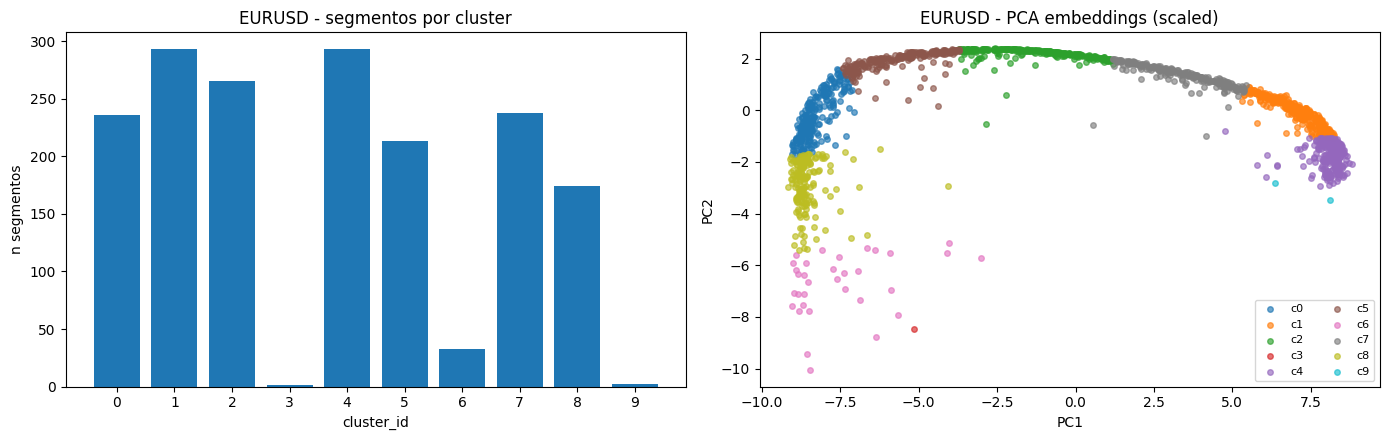

In [15]:
# =========================
# 11) Diagnosticos visuales
# =========================
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# a) conteo por cluster target
cnt = TAR_ASS['cluster_id'].value_counts().sort_index()
axes[0].bar(cnt.index.astype(str), cnt.values)
axes[0].set_title(f'{SYMBOL_TARGET} - segmentos por cluster')
axes[0].set_xlabel('cluster_id')
axes[0].set_ylabel('n segmentos')

# b) PCA de embeddings target coloreado por cluster
pca = PCA(n_components=2, random_state=SEED)
xy = pca.fit_transform(Z_TAR_ALL)
for cid in sorted(np.unique(cluster_tar)):
    m = cluster_tar == cid
    axes[1].scatter(xy[m, 0], xy[m, 1], s=16, alpha=0.65, label=f'c{cid}')
axes[1].set_title(f'{SYMBOL_TARGET} - PCA embeddings (scaled)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()


In [16]:
# =========================
# 12) Export npz embeddings target
# =========================
np.savez_compressed(
    EMB_NPZ,
    Z_target=Z_TAR,
    Z_target_scaled=Z_TAR_ALL,
    global_segment_id=DF_TAR['global_segment_id'].to_numpy(dtype='U64'),
    cluster_id=cluster_tar.astype(np.int32),
)
print('saved embeddings npz =', EMB_NPZ)


saved embeddings npz = ./phases/phase04_transfer_clustering/output_transfer_EURUSD_full_v2/EURUSD_embeddings_transfer.npz


## Resultado esperado de Phase 4 (v2)

1. Segmentos extraidos para EURUSD en el historico completo.
2. Embeddings mejorados por encoder de atencion con perdida compuesta.
3. Clusters asignados en EURUSD desde el espacio aprendido en USDJPY.
4. Segmentos target seleccionados usando perfiles de cluster de referencia.
